# 📊 Student Exams Analytics
**Comprehensive Data Analysis Report**  
Dataset: `Student_Data_Analytics_Analysis.xlsx`  
Objective: Extract actionable insights about student academic performance.

---

## 📦 Phase 1 — Setup & Data Loading

In [6]:
pip install numpy

Note: you may need to restart the kernel to use updated packages.


In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")

# Plot style
plt.rcParams["figure.dpi"] = 120
plt.rcParams["font.family"] = "sans-serif"
sns.set_theme(style="whitegrid", palette="Set2")

print("Libraries loaded ✅")

Libraries loaded ✅


In [13]:
# Load dataset
df = pd.read_excel("Student_Data_Analytics_Analysis.xlsx")

print(f"Rows: {df.shape[0]}  |  Columns: {df.shape[1]}")
df.head()

Rows: 86  |  Columns: 14


,No,Name,ID Number,Test 1 (100),Test 2 (100),AVERAGE,Final CA (30%),EXAMS,FINAL_SCORE,GRADE,Exam status,Exam mark (taken only),Test 2 minus Test 1,Test average minus exam
0,1,Fatmata Barrie,58855,87,88,87.5,26.25,78,80.85,A,Taken,78.0,1,9.5
1,2,Grace Kallon,60565,65,88,76.5,22.95,71,72.65,A,Taken,71.0,23,5.5
2,3,Momodu thoronka,60015,83,85,84.0,25.20,66,71.40,A,Taken,66.0,2,18.0
3,4,Morlai Ibrahim Kamara,62163,60,83,71.5,21.45,71,71.15,A,Taken,71.0,23,0.5
4,5,Maseray Lovetta Sesay,61325,89,89,89.0,26.70,62,70.10,A,Taken,62.0,0,27.0


## 🔍 Phase 2 — Data Understanding & Quality Check

In [14]:
# Data types & structure
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 86 entries, 0 to 85
Data columns (total 14 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   No                       86 non-null     int64  
 1   Name                     86 non-null     str    
 2   ID Number                86 non-null     int64  
 3   Test 1 (100)             86 non-null     int64  
 4   Test 2 (100)             86 non-null     int64  
 5   AVERAGE                  86 non-null     float64
 6   Final CA (30%)           86 non-null     float64
 7   EXAMS                    86 non-null     int64  
 8   FINAL_SCORE              84 non-null     float64
 9   GRADE                    84 non-null     str    
 10  Exam status              86 non-null     str    
 11  Exam mark (taken only)   84 non-null     float64
 12  Test 2 minus Test 1      86 non-null     int64  
 13  Test average minus exam  84 non-null     float64
dtypes: float64(5), int64(6), str(3)
memory 

In [15]:
# Descriptive statistics
df.describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
No,86.0,NaN,NaN,NaN,43.5,24.969982,1.0,22.25,43.5,64.75,86.0
Name,86,86,Fatmata Barrie,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
ID Number,86.0,NaN,NaN,NaN,58528.05814,8406.007033,12839.0,58631.5,59936.0,61514.25,65556.0
Test 1 (100),86.0,NaN,NaN,NaN,46.093023,17.711165,0.0,30.0,43.5,59.0,89.0
Test 2 (100),86.0,NaN,NaN,NaN,80.290698,15.729228,30.0,85.0,86.0,87.0,89.0
AVERAGE,86.0,NaN,NaN,NaN,63.19186,12.809961,30.0,57.5,63.25,71.25,89.0
Final CA (30%),86.0,NaN,NaN,NaN,18.957558,3.842988,9.0,17.25,18.975,21.375,26.7
EXAMS,86.0,NaN,NaN,NaN,42.034884,14.042329,0.0,33.0,42.0,50.0,78.0
FINAL_SCORE,84.0,NaN,NaN,NaN,49.241071,10.524327,26.75,42.125,48.55,55.275,80.85
GRADE,84,8,C,19,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [16]:
# Missing values analysis
missing = df.isnull().sum()
missing_pct = (missing / len(df) * 100).round(2)
missing_df = pd.DataFrame({"Missing Count": missing, "Missing %": missing_pct})
missing_df[missing_df["Missing Count"] > 0]

,Missing Count,Missing %
FINAL_SCORE,2,2.33
GRADE,2,2.33
Exam mark (taken only),2,2.33
Test average minus exam,2,2.33


In [17]:
# Investigate absent students (cause of NaN)
print("Students marked Absent:")
df[df["Exam status"] == "Absent"][["No", "Name", "ID Number", "Exam status", "EXAMS", "FINAL_SCORE", "GRADE"]]

Students marked Absent:


,No,Name,ID Number,Exam status,EXAMS,FINAL_SCORE,GRADE
84,85,Alhaji Bubakarr Jalloh,58852,Absent,0,NaN,NaN
85,86,Mohamed Bailo Bah,56616,Absent,0,NaN,NaN


In [18]:
# Grade & Exam status distribution
print("Grade Distribution:")
print(df["GRADE"].value_counts())
print("\nExam Status:")
print(df["Exam status"].value_counts())

Grade Distribution:
GRADE
C     19
C+    15
C-    14
F     14
B-    11
A      5
B+     3
B      3
Name: count, dtype: int64

Exam Status:
Exam status
Taken     84
Absent     2
Name: count, dtype: int64


## 📈 Phase 3 — Exploratory Data Analysis (EDA)

### 3.1 — Grade Distribution

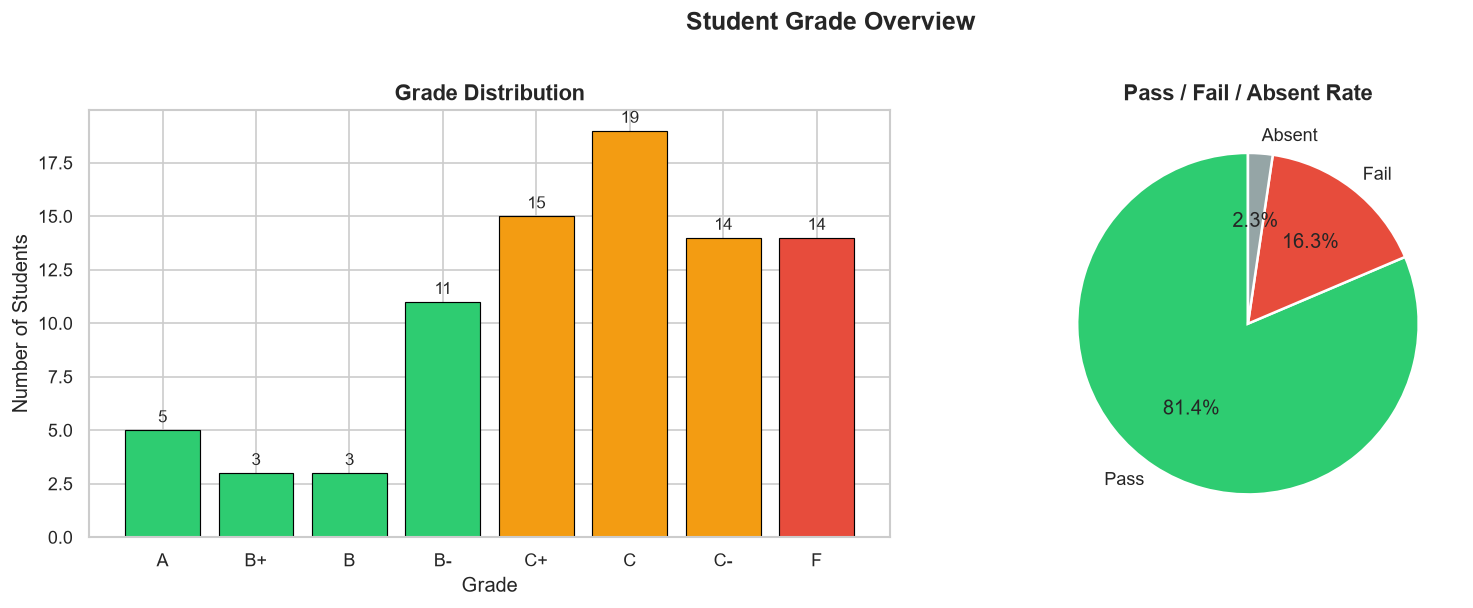

Fail rate: 16.7%  |  A grade: 6.0%


In [19]:
grade_order = ["A", "B+", "B", "B-", "C+", "C", "C-", "F"]
grade_counts = df["GRADE"].value_counts().reindex(grade_order, fill_value=0)
colors = ["#2ecc71" if g in ["A","B+","B","B-"] else "#f39c12" if g in ["C+","C","C-"] else "#e74c3c" for g in grade_order]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Grade bar chart
axes[0].bar(grade_order, grade_counts.values, color=colors, edgecolor="black", linewidth=0.7)
axes[0].set_title("Grade Distribution", fontsize=13, fontweight="bold")
axes[0].set_xlabel("Grade")
axes[0].set_ylabel("Number of Students")
for i, v in enumerate(grade_counts.values):
    axes[0].text(i, v + 0.2, str(v), ha="center", va="bottom", fontsize=10)

# Pie chart: Pass vs Fail
pass_fail = df["GRADE"].apply(
    lambda x: "Fail" if x == "F" else ("Pass" if pd.notna(x) else "Absent")
).value_counts()
axes[1].pie(pass_fail, labels=pass_fail.index, autopct="%1.1f%%",
            colors=["#2ecc71", "#e74c3c", "#95a5a6"], startangle=90,
            wedgeprops={"edgecolor":"white","linewidth":1.5})
axes[1].set_title("Pass / Fail / Absent Rate", fontsize=13, fontweight="bold")

plt.suptitle("Student Grade Overview", fontsize=15, fontweight="bold", y=1.01)
plt.tight_layout()
plt.savefig("grade_distribution.png", bbox_inches="tight")
plt.show()

total_graded = grade_counts.sum()
fail_rate = grade_counts.get("F", 0) / total_graded * 100
a_rate = grade_counts.get("A", 0) / total_graded * 100
print(f"Fail rate: {fail_rate:.1f}%  |  A grade: {a_rate:.1f}%")

### 3.2 — Score Distributions

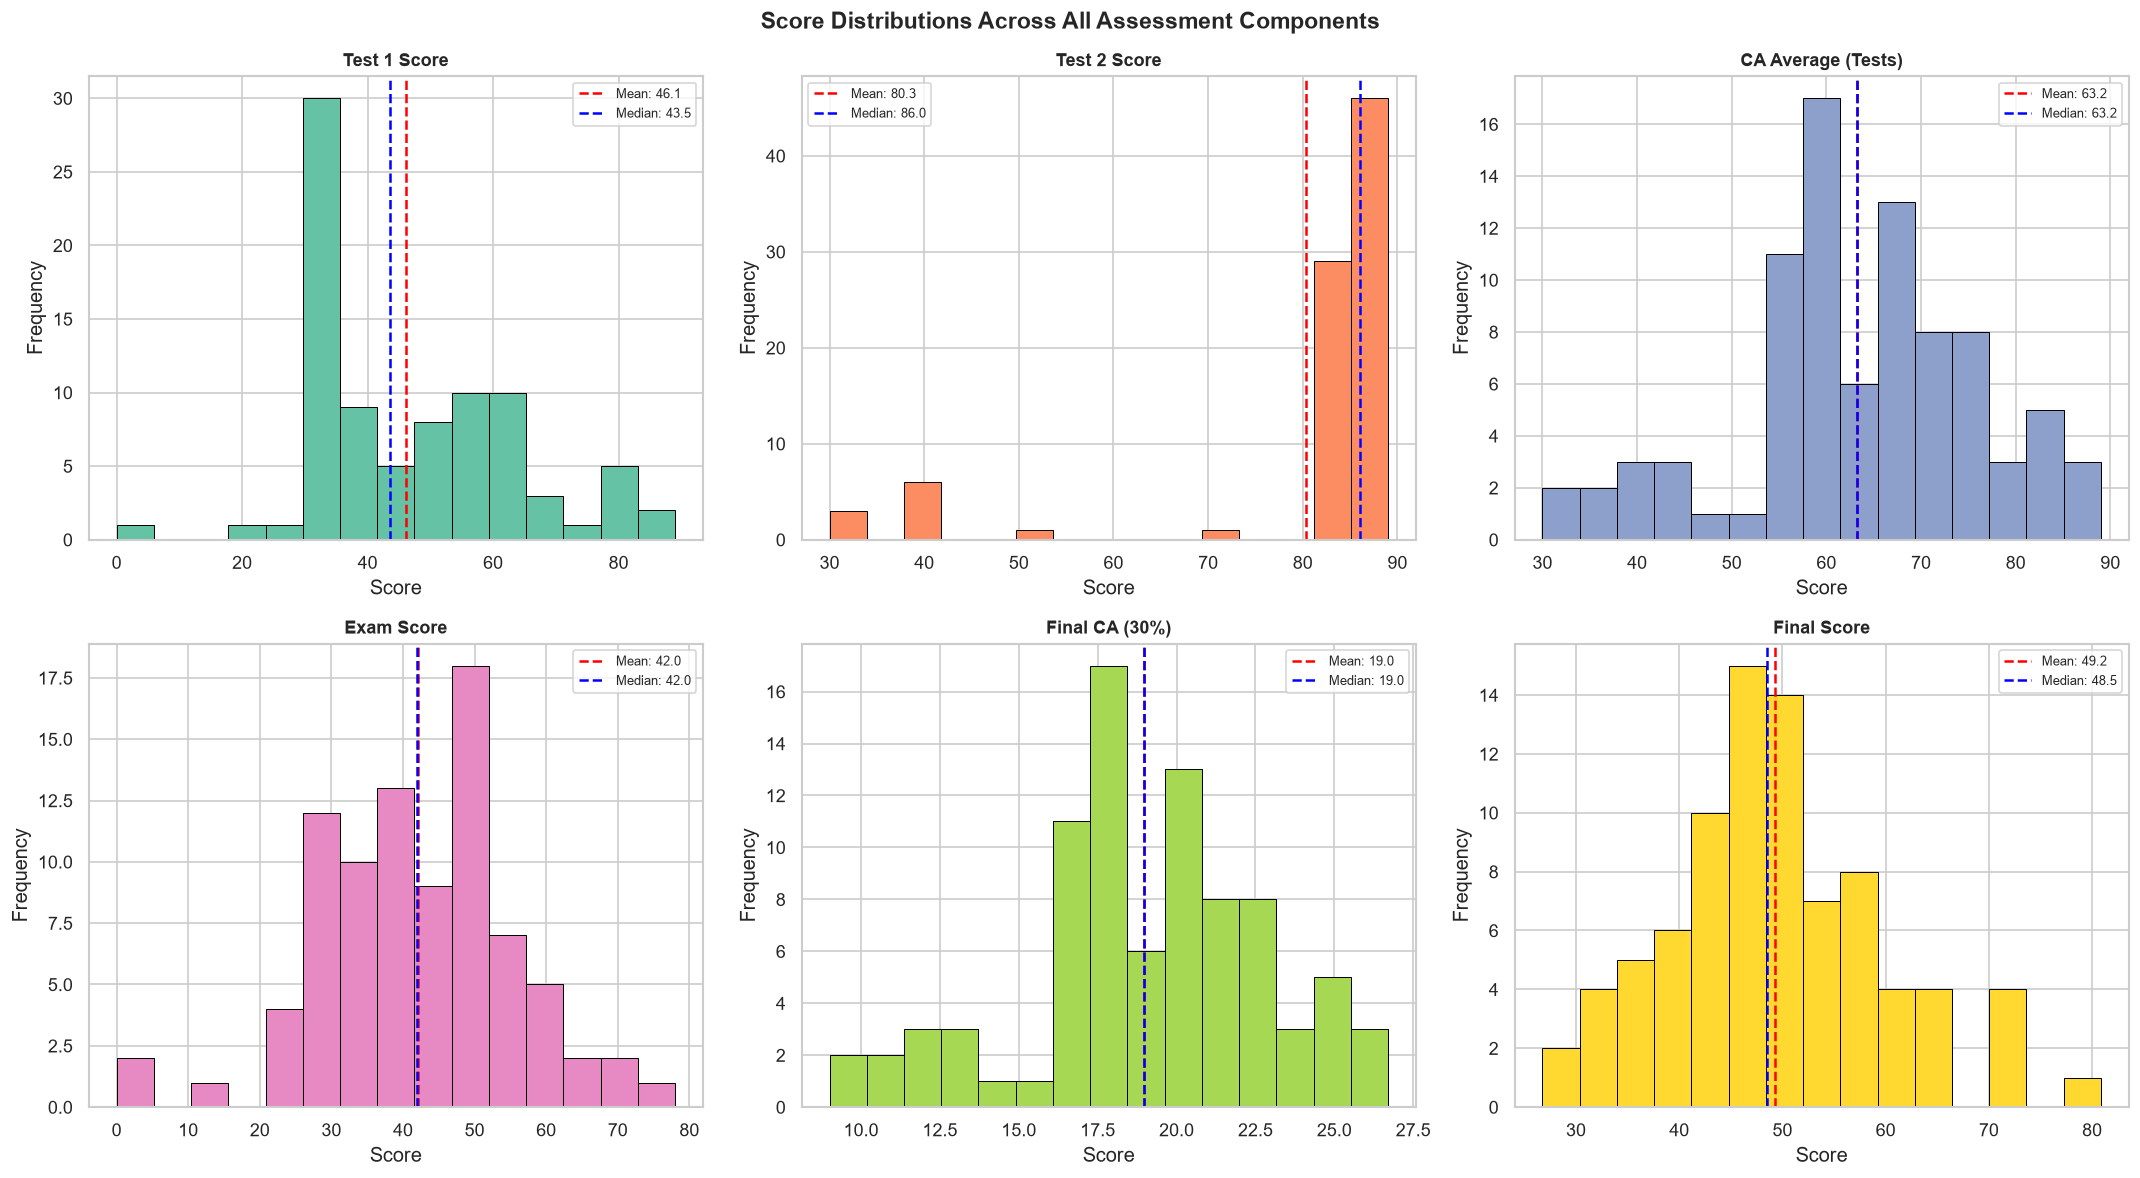

In [20]:
score_cols = ["Test 1 (100)", "Test 2 (100)", "AVERAGE", "EXAMS", "Final CA (30%)", "FINAL_SCORE"]
titles = ["Test 1 Score", "Test 2 Score", "CA Average (Tests)", "Exam Score", "Final CA (30%)", "Final Score"]

fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes = axes.flatten()
palette = sns.color_palette("Set2")

for i, (col, title) in enumerate(zip(score_cols, titles)):
    data = df[col].dropna()
    axes[i].hist(data, bins=15, edgecolor="black", color=palette[i % 6], linewidth=0.6)
    axes[i].axvline(data.mean(), color="red", linestyle="--", linewidth=1.5,
                    label=f"Mean: {data.mean():.1f}")
    axes[i].axvline(data.median(), color="blue", linestyle="--", linewidth=1.5,
                    label=f"Median: {data.median():.1f}")
    axes[i].set_title(title, fontsize=11, fontweight="bold")
    axes[i].set_xlabel("Score")
    axes[i].set_ylabel("Frequency")
    axes[i].legend(fontsize=8)

plt.suptitle("Score Distributions Across All Assessment Components", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.savefig("score_distributions.png", bbox_inches="tight")
plt.show()

### 3.3 — Box Plots (Outlier Detection)

TypeError: Axes.boxplot() got an unexpected keyword argument 'labels'. Did you mean 'label'?

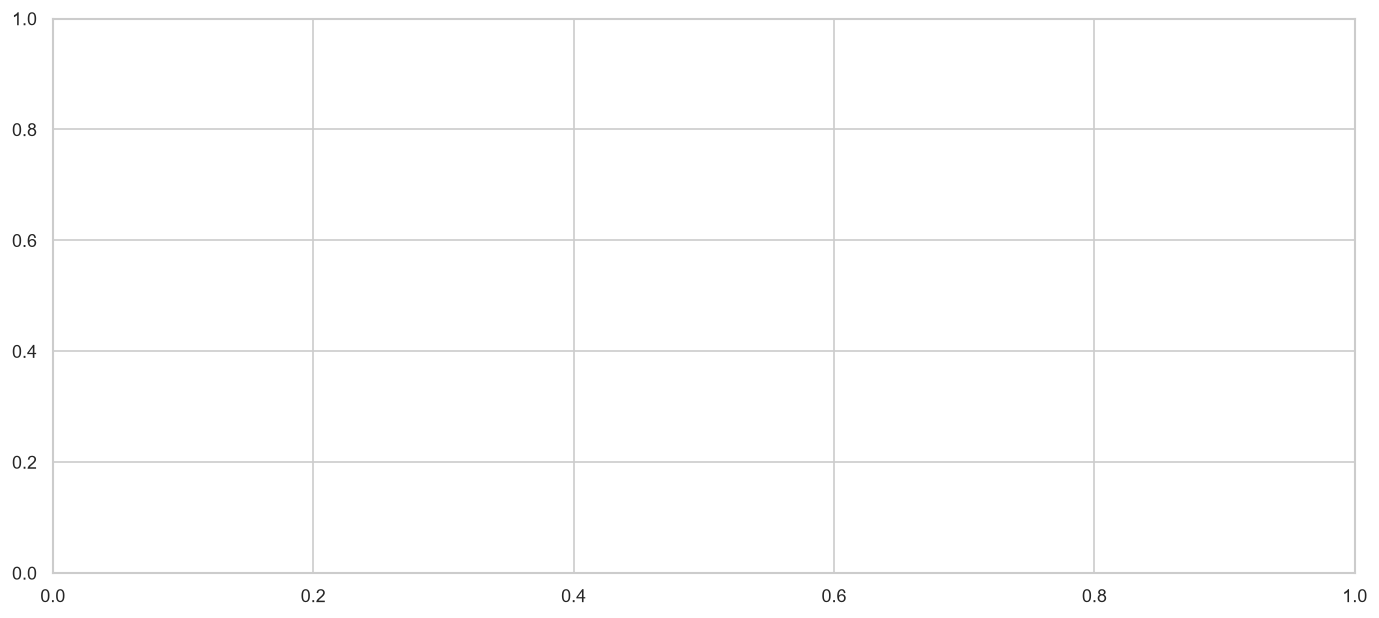

In [24]:
fig, ax = plt.subplots(figsize=(14, 6))

cols_bp = ["Test 1 (100)", "Test 2 (100)", "EXAMS", "FINAL_SCORE"]
labels_bp = ["Test 1", "Test 2", "Exam", "Final Score"]
data_bp = [df[c].dropna().values for c in cols_bp]

bp = ax.boxplot(data_bp, labels=labels_bp, patch_artist=True, notch=False)
colors_bp = ["#3498db", "#2ecc71", "#e74c3c", "#f39c12"]
for patch, color in zip(bp["boxes"], colors_bp):
    patch.set_facecolor(color)
    patch.set_alpha(0.7)

ax.set_title("Score Distributions — Box Plot (Outlier View)", fontsize=13, fontweight="bold")
ax.set_ylabel("Score")
ax.set_xlabel("Assessment Component")
plt.tight_layout()
plt.savefig("boxplots.png", bbox_inches="tight")
plt.show()

### 3.4 — Correlation Analysis

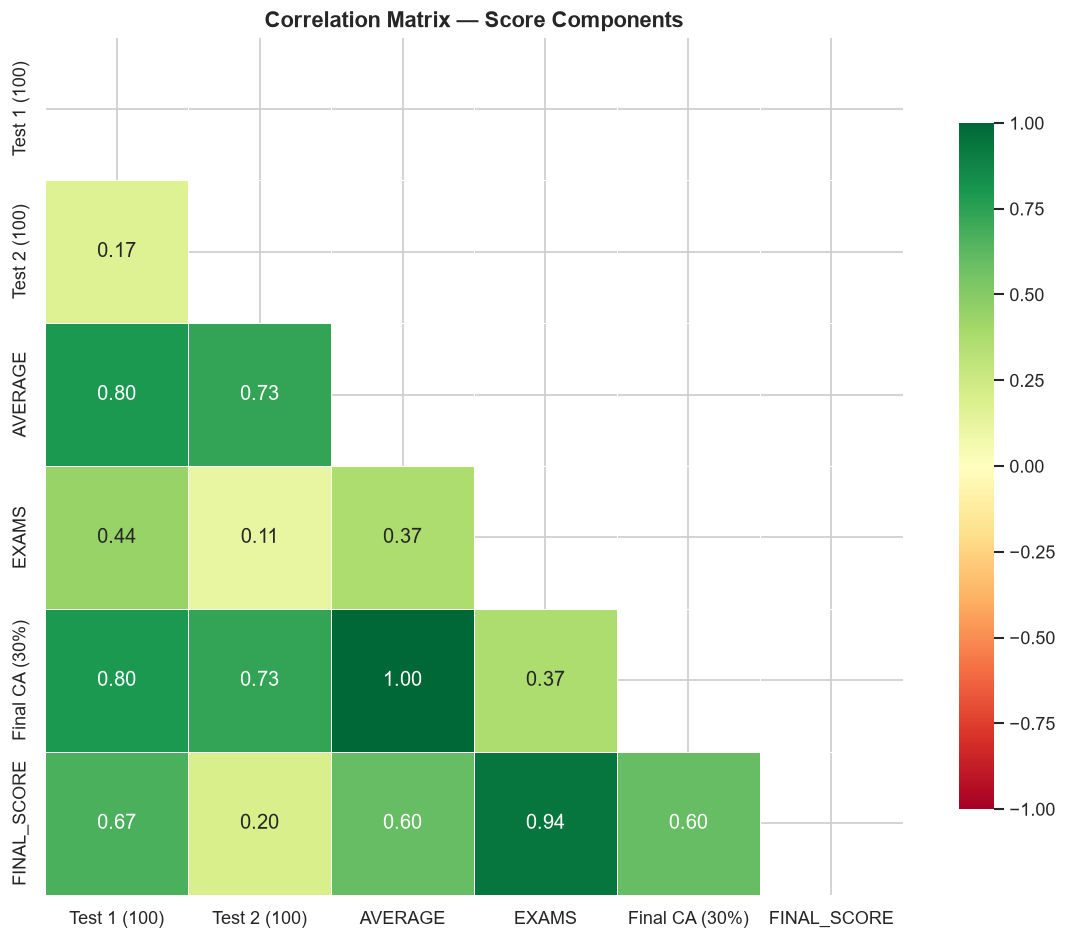

Key Correlations with FINAL_SCORE:
FINAL_SCORE       1.000000
EXAMS             0.940213
Test 1 (100)      0.671541
Final CA (30%)    0.598693
AVERAGE           0.598693
Test 2 (100)      0.199560


In [25]:
num_cols = ["Test 1 (100)", "Test 2 (100)", "AVERAGE", "EXAMS", "Final CA (30%)", "FINAL_SCORE"]
corr_matrix = df[num_cols].corr()

fig, ax = plt.subplots(figsize=(10, 8))
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="RdYlGn",
            mask=mask, square=True, ax=ax, linewidths=0.5,
            cbar_kws={"shrink": 0.8}, vmin=-1, vmax=1)
ax.set_title("Correlation Matrix — Score Components", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.savefig("correlation_heatmap.png", bbox_inches="tight")
plt.show()

print("Key Correlations with FINAL_SCORE:")
print(corr_matrix["FINAL_SCORE"].sort_values(ascending=False).to_string())

### 3.5 — Test 1 vs Test 2 Comparison

Improved: 80 (93.0%)  |  Declined: 3 (3.5%)  |  No change: 3


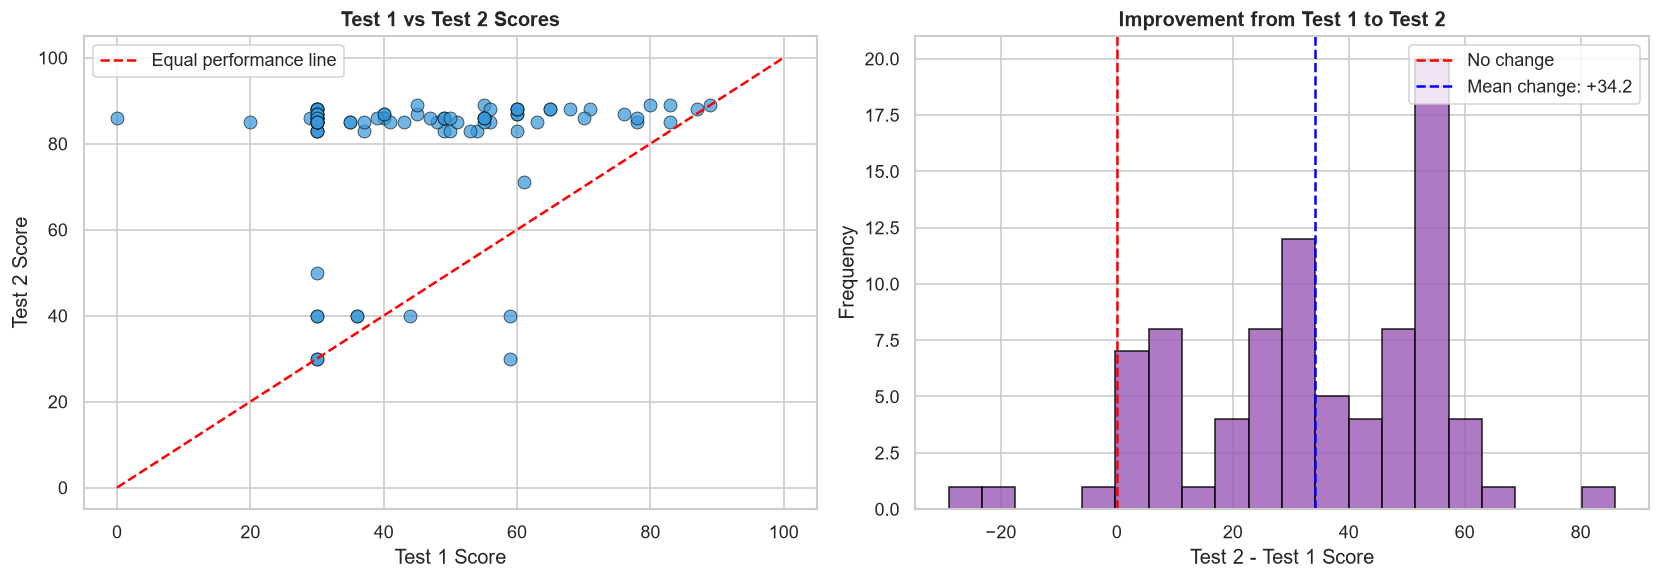

In [26]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Scatter plot
axes[0].scatter(df["Test 1 (100)"], df["Test 2 (100)"],
                alpha=0.7, color="#3498db", edgecolor="black", linewidth=0.5, s=60)
axes[0].plot([0, 100], [0, 100], "r--", linewidth=1.5, label="Equal performance line")
axes[0].set_xlabel("Test 1 Score")
axes[0].set_ylabel("Test 2 Score")
axes[0].set_title("Test 1 vs Test 2 Scores", fontsize=12, fontweight="bold")
axes[0].legend()

# Improvement distribution
improvement = df["Test 2 minus Test 1"]
axes[1].hist(improvement, bins=20, edgecolor="black", color="#9b59b6", alpha=0.8)
axes[1].axvline(0, color="red", linestyle="--", linewidth=1.5, label="No change")
axes[1].axvline(improvement.mean(), color="blue", linestyle="--", linewidth=1.5,
                label=f"Mean change: +{improvement.mean():.1f}")
axes[1].set_xlabel("Test 2 - Test 1 Score")
axes[1].set_ylabel("Frequency")
axes[1].set_title("Improvement from Test 1 to Test 2", fontsize=12, fontweight="bold")
axes[1].legend()

improved = (improvement > 0).sum()
declined = (improvement < 0).sum()
no_change = (improvement == 0).sum()
print(f"Improved: {improved} ({improved/len(df)*100:.1f}%)  |  "
      f"Declined: {declined} ({declined/len(df)*100:.1f}%)  |  No change: {no_change}")

plt.tight_layout()
plt.savefig("test_comparison.png", bbox_inches="tight")
plt.show()

## 👤 Phase 4 — Student-Level Insights

### 4.1 — Top 10 Performers

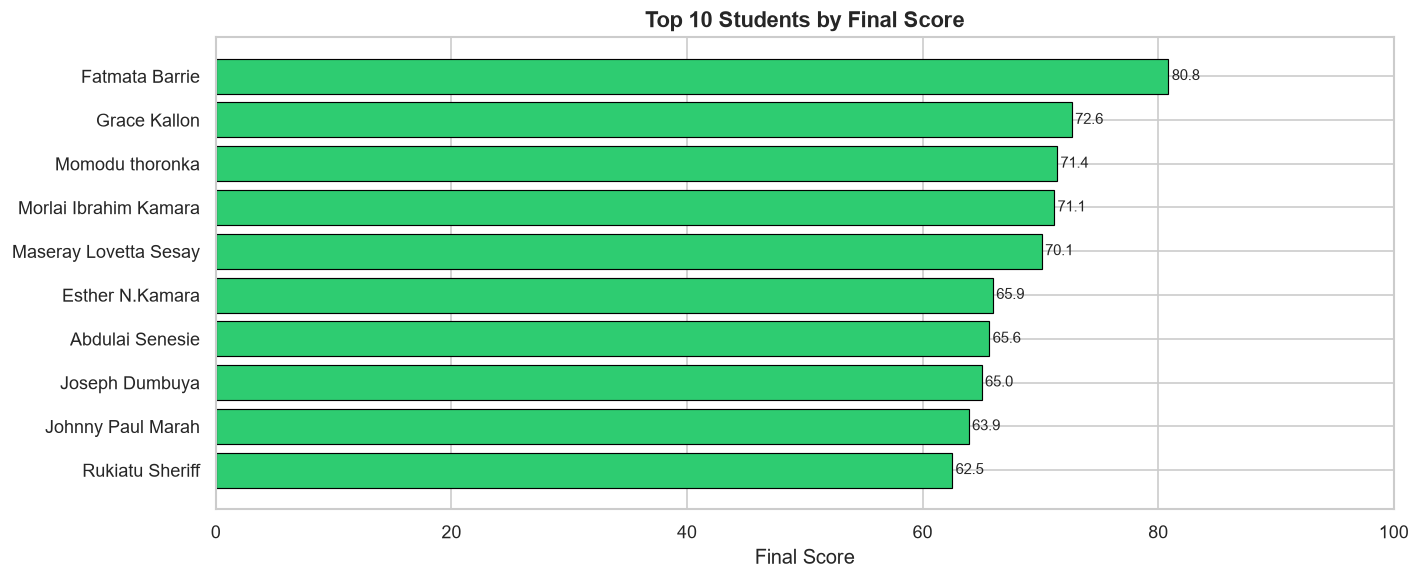

    No                   Name  Test 1 (100)  Test 2 (100)  EXAMS  FINAL_SCORE GRADE
1    1         Fatmata Barrie            87            88     78        80.85     A
2    2           Grace Kallon            65            88     71        72.65     A
3    3        Momodu thoronka            83            85     66        71.40     A
4    4  Morlai Ibrahim Kamara            60            83     71        71.15     A
5    5  Maseray Lovetta Sesay            89            89     62        70.10     A
6    6        Esther N.Kamara            80            89     58        65.95    B+
7    7        Abdulai Senesie            65            88     61        65.65    B+
8    8         Joseph Dumbuya            83            89     56        65.00    B+
9    9      Johnny Paul Marah            61            71     63        63.90     B
10  10        Rukiatu Sheriff            45            87     61        62.50     B


In [27]:
top10 = df[df["GRADE"].notna()].nlargest(10, "FINAL_SCORE")[
    ["No", "Name", "Test 1 (100)", "Test 2 (100)", "EXAMS", "FINAL_SCORE", "GRADE"]
].reset_index(drop=True)
top10.index += 1

fig, ax = plt.subplots(figsize=(12, 5))
bars = ax.barh(top10["Name"][::-1], top10["FINAL_SCORE"][::-1],
               color="#2ecc71", edgecolor="black", linewidth=0.7)
ax.set_xlabel("Final Score")
ax.set_title("Top 10 Students by Final Score", fontsize=13, fontweight="bold")
for bar in bars:
    ax.text(bar.get_width() + 0.3, bar.get_y() + bar.get_height() / 2,
            f"{bar.get_width():.1f}", va="center", fontsize=9)
ax.set_xlim(0, 100)
plt.tight_layout()
plt.savefig("top10_performers.png", bbox_inches="tight")
plt.show()

print(top10.to_string())

### 4.2 — Bottom 10 Performers (At-Risk Students)

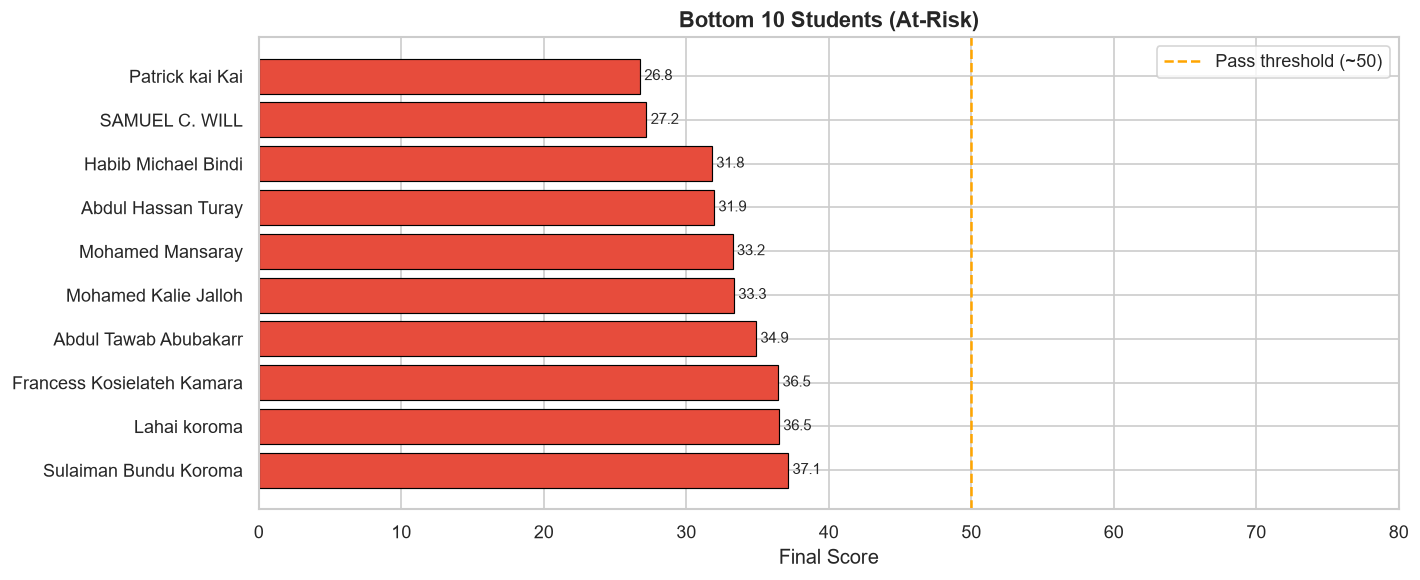

    No                        Name  Test 1 (100)  Test 2 (100)  EXAMS  FINAL_SCORE GRADE
1   83             Patrick kai Kai            40            87     11        26.75     F
2   82              SAMUEL C. WILL            30            30     26        27.20     F
3   81         Habib Michael Bindi             0            86     27        31.80     F
4   84          Abdul Hassan Turay            30            85     21        31.95     F
5   80            Mohamed Mansaray            20            85     25        33.25     F
6   79        Mohamed Kalie Jalloh            30            85     23        33.35     F
7   78       Abdul Tawab Abubakarr            30            86     25        34.90     F
8   77  Francess Kosielateh Kamara            30            87     27        36.45     F
9   76                Lahai koroma            37            85     26        36.50     F
10  75       Sulaiman Bundu Koroma            30            87     28        37.15     F


In [28]:
bottom10 = df[df["GRADE"].notna()].nsmallest(10, "FINAL_SCORE")[
    ["No", "Name", "Test 1 (100)", "Test 2 (100)", "EXAMS", "FINAL_SCORE", "GRADE"]
].reset_index(drop=True)
bottom10.index += 1

fig, ax = plt.subplots(figsize=(12, 5))
bars = ax.barh(bottom10["Name"][::-1], bottom10["FINAL_SCORE"][::-1],
               color="#e74c3c", edgecolor="black", linewidth=0.7)
ax.set_xlabel("Final Score")
ax.set_title("Bottom 10 Students (At-Risk)", fontsize=13, fontweight="bold")
ax.axvline(50, color="orange", linestyle="--", linewidth=1.5, label="Pass threshold (~50)")
for bar in bars:
    ax.text(bar.get_width() + 0.3, bar.get_y() + bar.get_height() / 2,
            f"{bar.get_width():.1f}", va="center", fontsize=9)
ax.set_xlim(0, 80)
ax.legend()
plt.tight_layout()
plt.savefig("bottom10_atrisk.png", bbox_inches="tight")
plt.show()

print(bottom10.to_string())

### 4.3 — CA Average vs Exam Score (by Grade)

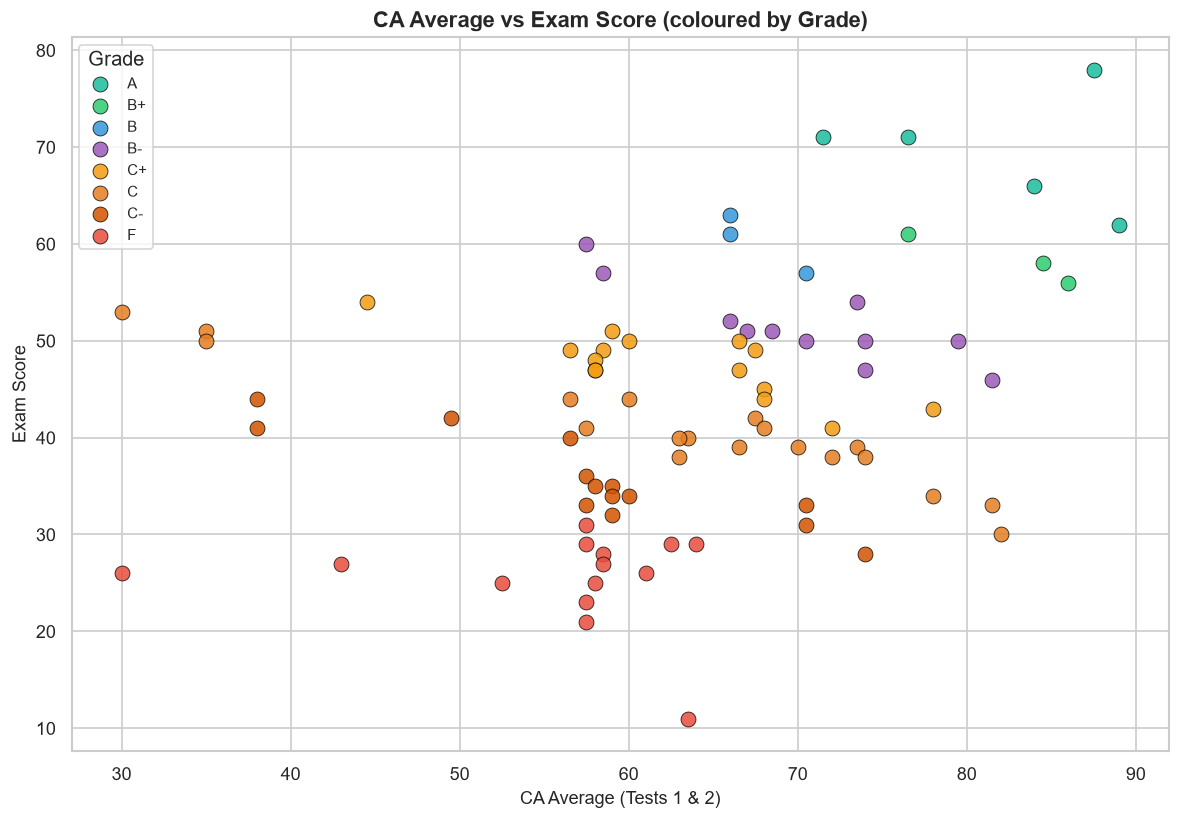

In [29]:
grade_order = ["A", "B+", "B", "B-", "C+", "C", "C-", "F"]
grade_colors = {
    "A": "#1abc9c", "B+": "#2ecc71", "B": "#3498db", "B-": "#9b59b6",
    "C+": "#f39c12", "C": "#e67e22", "C-": "#d35400", "F": "#e74c3c"
}

fig, ax = plt.subplots(figsize=(10, 7))
for grade in grade_order:
    subset = df[df["GRADE"] == grade]
    ax.scatter(subset["AVERAGE"], subset["EXAMS"],
               label=grade, color=grade_colors.get(grade, "grey"),
               s=80, alpha=0.85, edgecolor="black", linewidth=0.5)

ax.set_xlabel("CA Average (Tests 1 & 2)", fontsize=11)
ax.set_ylabel("Exam Score", fontsize=11)
ax.set_title("CA Average vs Exam Score (coloured by Grade)", fontsize=13, fontweight="bold")
ax.legend(title="Grade", loc="upper left", fontsize=9)
plt.tight_layout()
plt.savefig("ca_vs_exam.png", bbox_inches="tight")
plt.show()

### 4.4 — Performance Consistency: CA vs Exam Gap

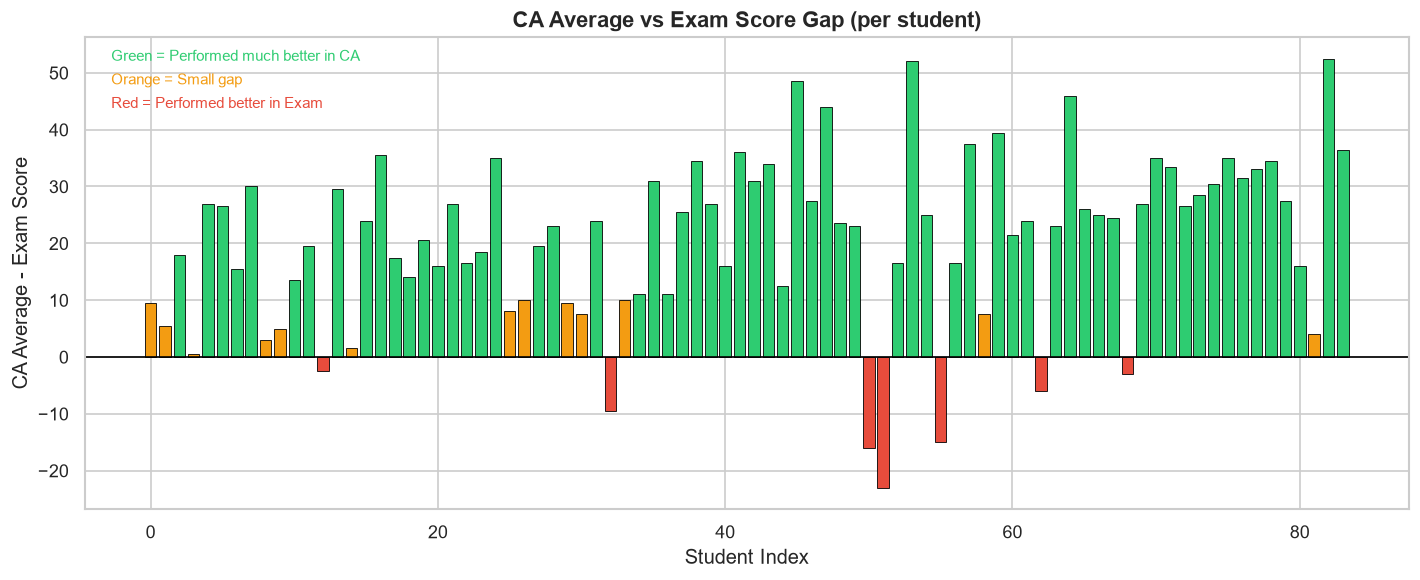

Students who scored higher in exam than CA : 7
Students who scored higher in CA than exam : 77
Mean CA-Exam gap                           : 20.7 points


In [30]:
gap = df["Test average minus exam"].dropna()
colors_gap = ["#e74c3c" if v < 0 else "#2ecc71" if v > 10 else "#f39c12" for v in gap]

fig, ax = plt.subplots(figsize=(12, 5))
ax.bar(range(len(gap)), gap.values, color=colors_gap, edgecolor="black", linewidth=0.5)
ax.axhline(0, color="black", linewidth=1)
ax.set_title("CA Average vs Exam Score Gap (per student)", fontsize=13, fontweight="bold")
ax.set_xlabel("Student Index")
ax.set_ylabel("CA Average - Exam Score")
ax.text(0.02, 0.95, "Green = Performed much better in CA",
        transform=ax.transAxes, color="#2ecc71", fontsize=9)
ax.text(0.02, 0.90, "Orange = Small gap",
        transform=ax.transAxes, color="#f39c12", fontsize=9)
ax.text(0.02, 0.85, "Red = Performed better in Exam",
        transform=ax.transAxes, color="#e74c3c", fontsize=9)
plt.tight_layout()
plt.savefig("ca_exam_gap.png", bbox_inches="tight")
plt.show()

print(f"Students who scored higher in exam than CA : {(gap < 0).sum()}")
print(f"Students who scored higher in CA than exam : {(gap > 0).sum()}")
print(f"Mean CA-Exam gap                           : {gap.mean():.1f} points")

## 📊 Phase 5 — Summary Dashboard

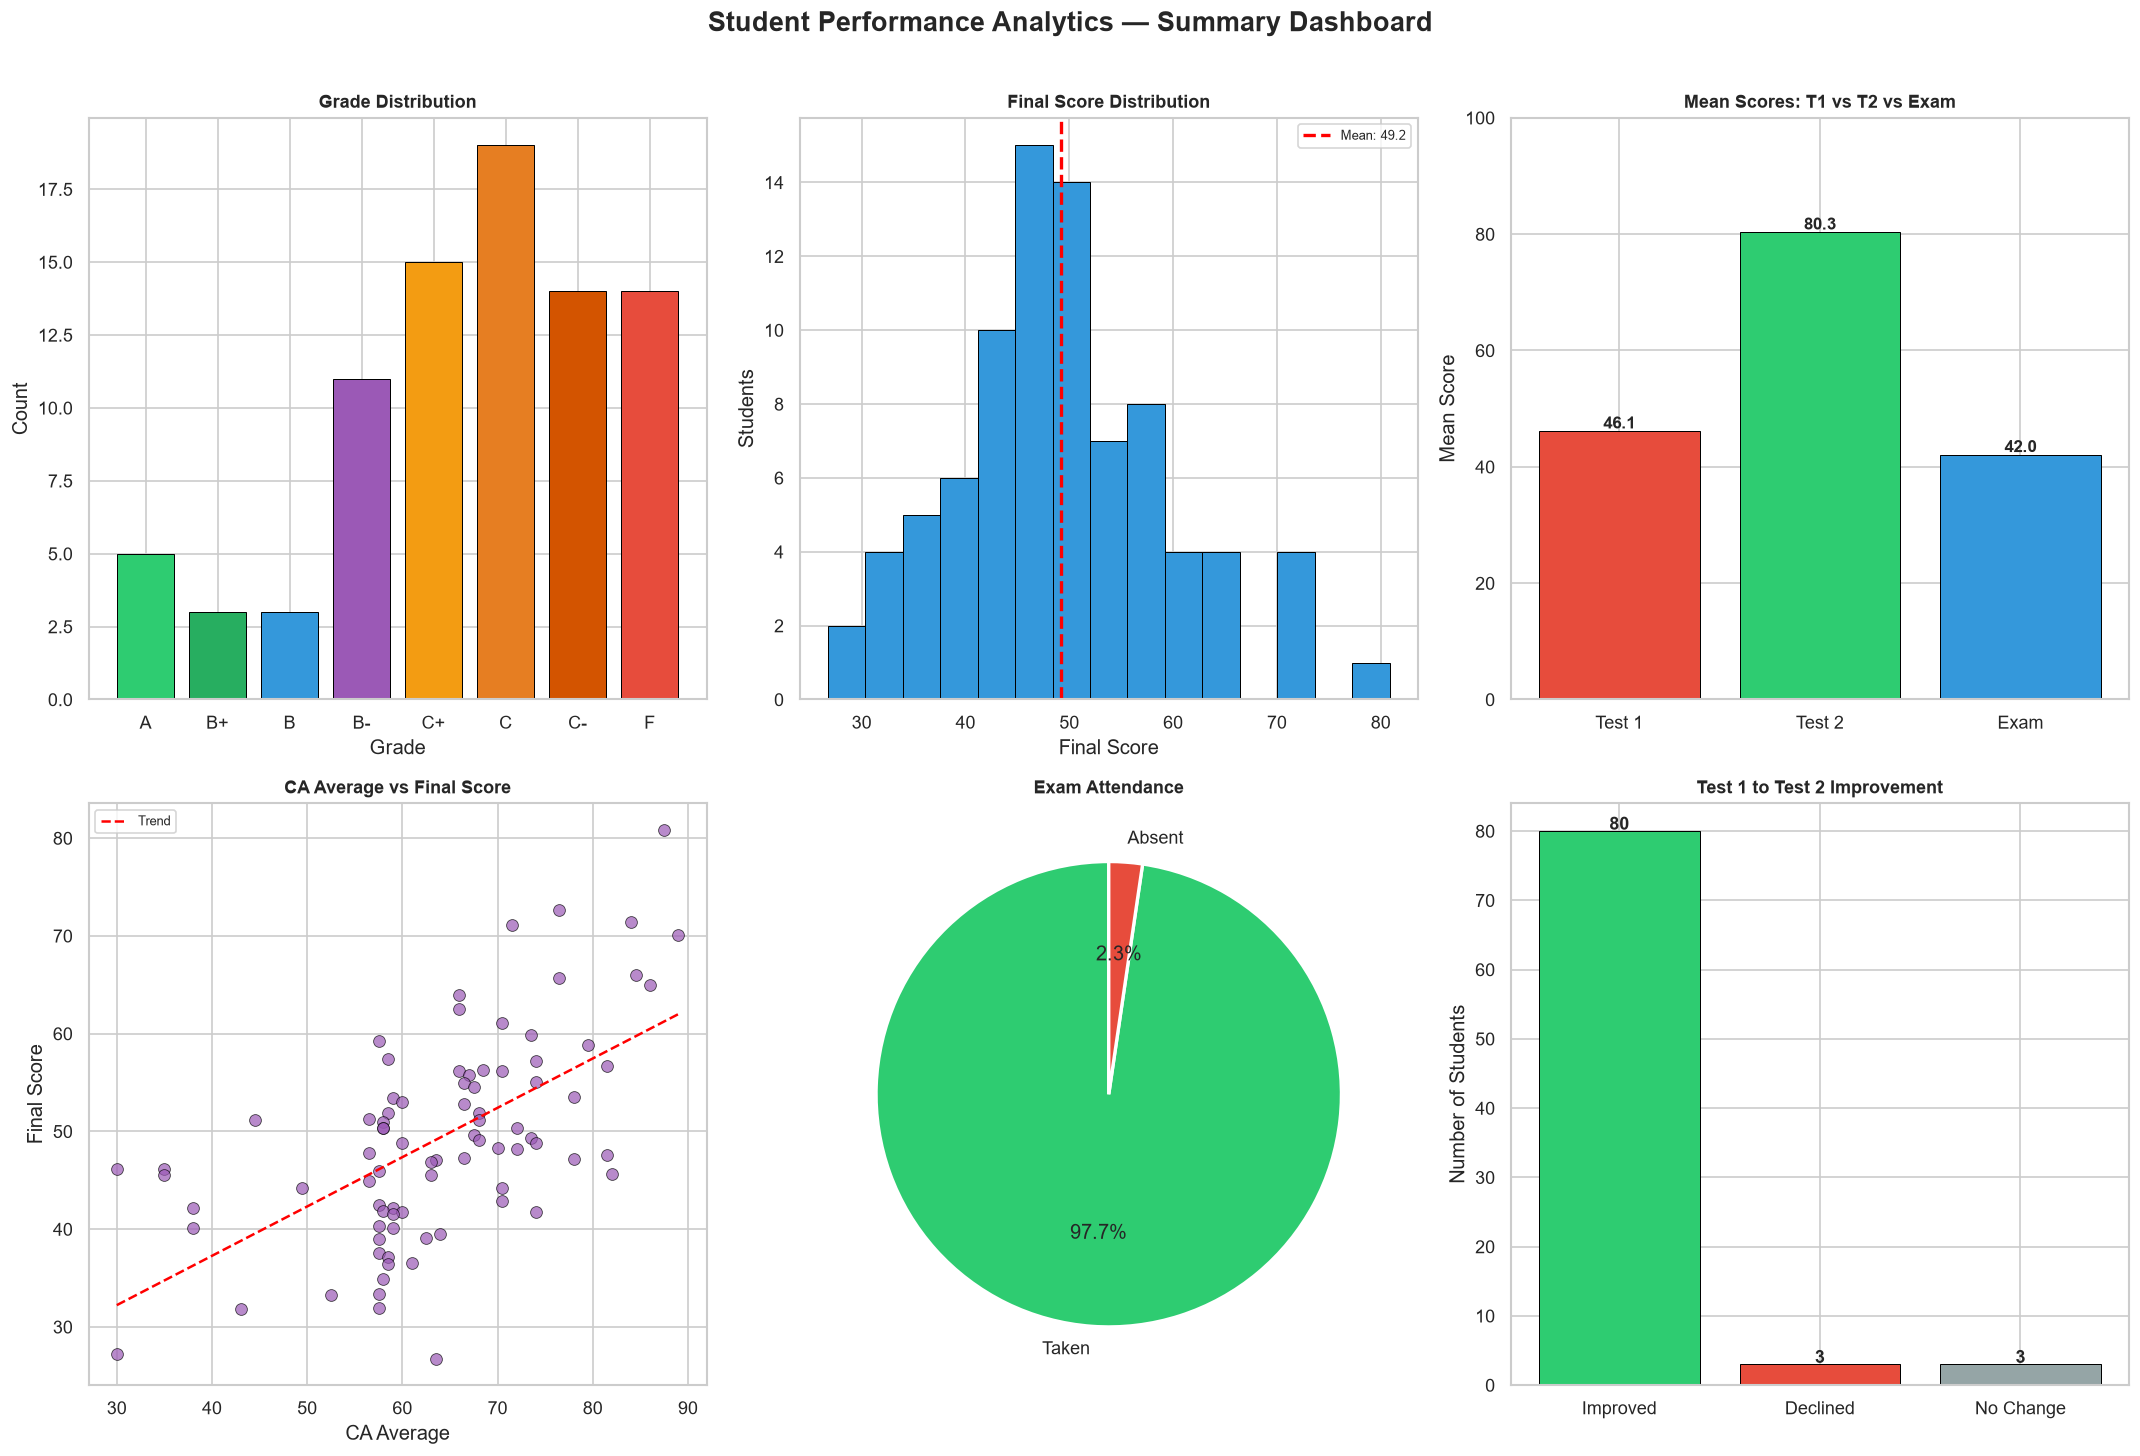

In [31]:
grade_order = ["A", "B+", "B", "B-", "C+", "C", "C-", "F"]
grade_counts = df["GRADE"].value_counts().reindex(grade_order, fill_value=0)

fig = plt.figure(figsize=(18, 12))
fig.suptitle("Student Performance Analytics — Summary Dashboard",
             fontsize=16, fontweight="bold", y=1.01)

# 1. Grade distribution
ax1 = fig.add_subplot(2, 3, 1)
colors_g = ["#2ecc71","#27ae60","#3498db","#9b59b6","#f39c12","#e67e22","#d35400","#e74c3c"]
ax1.bar(grade_order, grade_counts, color=colors_g, edgecolor="black", linewidth=0.6)
ax1.set_title("Grade Distribution", fontsize=11, fontweight="bold")
ax1.set_xlabel("Grade"); ax1.set_ylabel("Count")

# 2. Final score histogram
ax2 = fig.add_subplot(2, 3, 2)
final_data = df["FINAL_SCORE"].dropna()
ax2.hist(final_data, bins=15, color="#3498db", edgecolor="black", linewidth=0.6)
ax2.axvline(final_data.mean(), color="red", linestyle="--", linewidth=2,
            label=f"Mean: {final_data.mean():.1f}")
ax2.set_title("Final Score Distribution", fontsize=11, fontweight="bold")
ax2.set_xlabel("Final Score"); ax2.set_ylabel("Students"); ax2.legend(fontsize=8)

# 3. Mean scores comparison
ax3 = fig.add_subplot(2, 3, 3)
means = [df["Test 1 (100)"].mean(), df["Test 2 (100)"].mean(), df["EXAMS"].mean()]
bars3 = ax3.bar(["Test 1", "Test 2", "Exam"], means,
                color=["#e74c3c","#2ecc71","#3498db"], edgecolor="black", linewidth=0.6)
for bar in bars3:
    ax3.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.5,
             f"{bar.get_height():.1f}", ha="center", fontsize=10, fontweight="bold")
ax3.set_title("Mean Scores: T1 vs T2 vs Exam", fontsize=11, fontweight="bold")
ax3.set_ylabel("Mean Score"); ax3.set_ylim(0, 100)

# 4. Scatter: CA Average vs Final Score
ax4 = fig.add_subplot(2, 3, 4)
valid = df[["AVERAGE","FINAL_SCORE"]].dropna()
ax4.scatter(valid["AVERAGE"], valid["FINAL_SCORE"],
            alpha=0.7, color="#9b59b6", edgecolor="black", linewidth=0.5, s=50)
z = np.polyfit(valid["AVERAGE"], valid["FINAL_SCORE"], 1)
p = np.poly1d(z)
x_line = np.linspace(valid["AVERAGE"].min(), valid["AVERAGE"].max(), 100)
ax4.plot(x_line, p(x_line), "r--", linewidth=1.5, label="Trend")
ax4.set_title("CA Average vs Final Score", fontsize=11, fontweight="bold")
ax4.set_xlabel("CA Average"); ax4.set_ylabel("Final Score"); ax4.legend(fontsize=8)

# 5. Exam attendance pie
ax5 = fig.add_subplot(2, 3, 5)
attendance = df["Exam status"].value_counts()
ax5.pie(attendance, labels=attendance.index, autopct="%1.1f%%",
        colors=["#2ecc71","#e74c3c"], startangle=90,
        wedgeprops={"edgecolor":"white","linewidth":2})
ax5.set_title("Exam Attendance", fontsize=11, fontweight="bold")

# 6. Test 1 -> Test 2 improvement
ax6 = fig.add_subplot(2, 3, 6)
improved = (df["Test 2 minus Test 1"] > 0).sum()
declined = (df["Test 2 minus Test 1"] < 0).sum()
no_change = (df["Test 2 minus Test 1"] == 0).sum()
bars6 = ax6.bar(["Improved", "Declined", "No Change"],
                [improved, declined, no_change],
                color=["#2ecc71","#e74c3c","#95a5a6"],
                edgecolor="black", linewidth=0.6)
for bar in bars6:
    ax6.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.2,
             str(int(bar.get_height())), ha="center", fontsize=11, fontweight="bold")
ax6.set_title("Test 1 to Test 2 Improvement", fontsize=11, fontweight="bold")
ax6.set_ylabel("Number of Students")

plt.tight_layout()
plt.savefig("summary_dashboard.png", bbox_inches="tight", dpi=150)
plt.show()

## 📝 Phase 6 — Key Findings & Recommendations

In [32]:
grade_order = ["A", "B+", "B", "B-", "C+", "C", "C-", "F"]
grade_counts = df["GRADE"].value_counts().reindex(grade_order, fill_value=0)

total = len(df)
taken = (df["Exam status"] == "Taken").sum()
absent = (df["Exam status"] == "Absent").sum()
passed = df["GRADE"].isin(["A","B+","B","B-","C+","C","C-"]).sum()
failed = (df["GRADE"] == "F").sum()
mean_t1 = df["Test 1 (100)"].mean()
mean_t2 = df["Test 2 (100)"].mean()
mean_exam = df["EXAMS"].mean()
mean_final = df["FINAL_SCORE"].mean()
improved = (df["Test 2 minus Test 1"] > 0).sum()

SEP = "=" * 60

print(SEP)
print("       STUDENT ANALYTICS — KEY FINDINGS SUMMARY")
print(SEP)
print(f"  Total Students           : {total}")
print(f"  Exam Takers              : {taken} ({taken/total*100:.1f}%)")
print(f"  Exam Absentees           : {absent}")
print(f"  Students Passed          : {passed} ({passed/total*100:.1f}%)")
print(f"  Students Failed (Grade F): {failed} ({failed/total*100:.1f}%)")
print()
print(f"  Mean Test 1 Score        : {mean_t1:.1f} / 100")
print(f"  Mean Test 2 Score        : {mean_t2:.1f} / 100  (+{mean_t2-mean_t1:.1f} from Test 1)")
print(f"  Mean Exam Score          : {mean_exam:.1f} / 100")
print(f"  Mean Final Score         : {mean_final:.1f} / 100")
print()
print(f"  Students Improved T1->T2 : {improved} ({improved/total*100:.1f}%)")
print()
print("  Grade Distribution:")
for g in grade_order:
    count = grade_counts.get(g, 0)
    bar = chr(9608) * count
    print(f"    {g:3s}: {bar} ({count})")
print()
print("RECOMMENDATIONS:")
print("-" * 60)
print(f"1. EXAM PERFORMANCE GAP: Mean exam ({mean_exam:.1f}) vs Test 2 ({mean_t2:.1f})")
print(f"   — a {mean_t2-mean_exam:.1f}-pt drop. Students need better exam preparation.")
print(f"2. HIGH FAIL RATE: {failed/total*100:.1f}% of students scored grade F.")
print("   Targeted remediation & early intervention is needed.")
print(f"3. IMPROVEMENT TREND: {improved/total*100:.1f}% improved Test1->Test2.")
print("   Continue the teaching approach used between tests.")
print(f"4. TEST 1 WEAKNESS: Mean only {mean_t1:.1f}/100 vs Test 2 mean {mean_t2:.1f}.")
print("   Initial teaching delivery/pace should be reviewed.")
print("5. CA vs EXAM GAP: Most students perform significantly better")
print("   in CA than in the final exam — exam anxiety or poor")
print("   revision strategy may be contributing factors.")
print("6. AT-RISK STUDENTS: Bottom 10 students (see chart) need")
print("   individual mentoring and academic support plans.")
print(SEP)

       STUDENT ANALYTICS — KEY FINDINGS SUMMARY
  Total Students           : 86
  Exam Takers              : 84 (97.7%)
  Exam Absentees           : 2
  Students Passed          : 70 (81.4%)
  Students Failed (Grade F): 14 (16.3%)

  Mean Test 1 Score        : 46.1 / 100
  Mean Test 2 Score        : 80.3 / 100  (+34.2 from Test 1)
  Mean Exam Score          : 42.0 / 100
  Mean Final Score         : 49.2 / 100

  Students Improved T1->T2 : 80 (93.0%)

  Grade Distribution:
    A  : █████ (5)
    B+ : ███ (3)
    B  : ███ (3)
    B- : ███████████ (11)
    C+ : ███████████████ (15)
    C  : ███████████████████ (19)
    C- : ██████████████ (14)
    F  : ██████████████ (14)

RECOMMENDATIONS:
------------------------------------------------------------
1. EXAM PERFORMANCE GAP: Mean exam (42.0) vs Test 2 (80.3)
   — a 38.3-pt drop. Students need better exam preparation.
2. HIGH FAIL RATE: 16.3% of students scored grade F.
   Targeted remediation & early intervention is needed.
3. IMPROVEMENT 

---
**Analysis complete!** 🎉  
All charts saved as PNG files in the working directory.  

### Charts Generated:
- `grade_distribution.png` — Grade bar chart + Pass/Fail pie
- `score_distributions.png` — Histograms for all 6 score columns
- `boxplots.png` — Box plots for outlier detection
- `correlation_heatmap.png` — Pearson correlation matrix
- `test_comparison.png` — T1 vs T2 scatter + improvement histogram
- `top10_performers.png` — Top 10 students
- `bottom10_atrisk.png` — Bottom 10 / at-risk students
- `ca_vs_exam.png` — CA vs Exam by grade
- `ca_exam_gap.png` — Per-student CA-Exam gap
- `summary_dashboard.png` — Full summary dashboard
